# ``meshlab`` - Tutorial 5

**Airfoil with a translated slat and flap**


## 1. Import packages
---


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from functions.split_flap import split_curve
from functions.transform_curve import transform_curve
from functions.unit_vector import unit_vector

from meshlab.core import Mesh, Curve, Contour, Front
from meshlab.operations import (
    insert_contour, initialize_front, compute_normals,
    smooth_normals, advance_front, split_curve,
)
from meshlab.utils import plot_mesh
from meshlab.export import export_mesh

## 2. Geometries definition
---


Original NACA 2412 airfoil


In [47]:
airfoil = np.loadtxt("./data/NACA-2412.dat")

In [51]:
n1 = 40
n2 = 70
t1 = unit_vector([-1, -0.5])
t2 = unit_vector([0.5, 1])

body, slat = split_curve(airfoil, n1, t1, n2, t2, 0.1)
body = transform_curve(body, dx=0.1)
slat = transform_curve(slat, dy=-0.02, theta=15.0)

n3 = 25
n4 = 51
t3 = unit_vector([1, 1])
t4 = unit_vector([-1, 0.1])

body, flap = split_curve(body, n3, t3, n4, t4, 0.05)
flap = transform_curve(flap, dx=0.15, dy=-0.08, theta=-15.0)


Slat, main airfoil and flap


In [53]:
slat = Contour("slat", [Curve("slat", slat)])
body = Contour("body", [Curve("body", body)])
flap = Contour("flap", [Curve("flap", flap)])

## 3. Creating mesh surfaces
---


In [54]:
mesh = Mesh(dim=2, vertices_capacity=5000, cells_capacity=5000)
insert_contour(mesh, slat)
insert_contour(mesh, body)
insert_contour(mesh, flap)

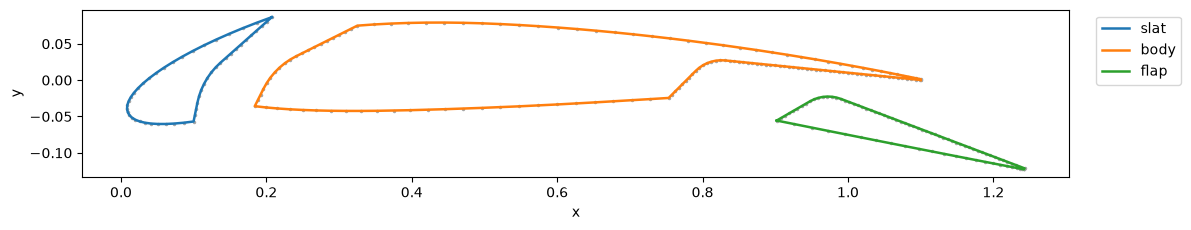

In [55]:
figure, ax = plot_mesh(mesh, show=False)

figure.set_size_inches(12, 5)
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0))
figure.tight_layout()

plt.show()

## 4. Initialize fronts
---


In [56]:
# Thin layers leave the gaps open for the residual Gmsh mesh
num_layers = 20
height = 0.0002
growth_rate = 1.10
smooth_steps = 3
relaxation = 0.5

slat_front = Front("slat_front", int_dtype=mesh.int_dtype)
main_front = Front("main_front", int_dtype=mesh.int_dtype)
flap_front = Front("flap_front", int_dtype=mesh.int_dtype)

initialize_front(mesh, slat_front, curves=["slat"])
initialize_front(mesh, main_front, curves=["body"])
initialize_front(mesh, flap_front, curves=["flap"])

fronts = [slat_front, main_front, flap_front]

## 5. Growing boundary layers
---


In [57]:
h = height
for _ in range(num_layers):
    for front in fronts:
        normals = compute_normals(mesh, front, method="bisector")
        for _ in range(smooth_steps):
            normals, _ = smooth_normals(mesh, front, normals, relaxation)
        advance_front(mesh, front, normals, h)
    h *= growth_rate

Visualize mesh


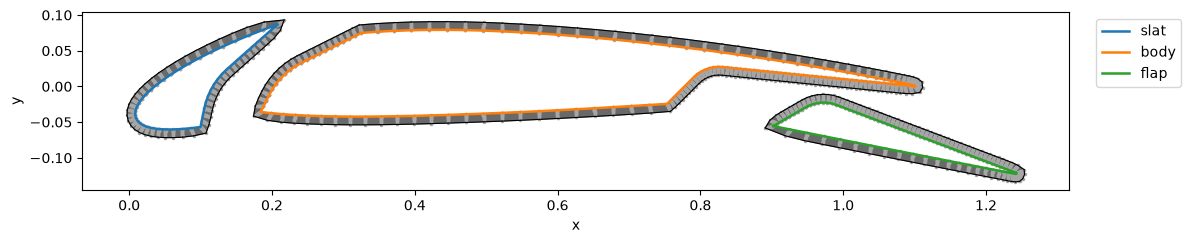

In [58]:
figure, ax = plot_mesh(mesh, show=False)

figure.set_size_inches(12, 5)
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0))
figure.tight_layout()

plt.show()

## 6. Circular domain
---


In [60]:
farfield_radius = 10.0
farfield_points = 100

# External contour in a clockwise direction
angles = np.linspace(0.0, -2.0 * np.pi, farfield_points, endpoint=False)
points = farfield_radius * np.column_stack((np.cos(angles), np.sin(angles)))
points = np.vstack((points, points[0]))

farfield = Contour("outer_domain", [Curve("freestream", points)])
insert_contour(mesh, farfield)

## 7. Generate and export the Gmsh mesh
---


In [63]:
thickness = 0.1
mesh_size = 0.3
show_gmsh = False             # True opens the interactive Gmsh window
filename = "./results/slat-airfoil-flap.msh"

In [ ]:
export_mesh(
    mesh,
    fronts=fronts,
    filename=filename,
    mode="planar",
    thickness=thickness,
    mesh_size=mesh_size,
    show=show_gmsh,
)

print(filename)

./results/slat-airfoil-flap.msh


### Convert to OpenFOAM
---
- Run in a terminal using a prepared OpenFOAM case:
- Set writePrecision to 16 in system/controlDict before conversion.
- gmshToFoam /path/to/tutorials/results/NACA-2412.msh
- Set frontAndBack to empty in constant/polyMesh/boundary and the field files.
- checkMesh -allTopology -allGeometry